#### Phase 8 - Sense-Making Decision Layer

Loads what `src/decision.py` produced (`results/decision/`, `decision.confidence_threshold` in `config.yaml`). Nothing is recomputed here.

A reading is **APPROVED** if its confidence is at or above the threshold and the sensing gate passed, otherwise **FLAGGED** for review. The threshold is chosen on validation and reported on test.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(str(Path.cwd().parent / "src"))
from config import CONFIG, resolve_path
from decision import load_fused, plot_decision_flow

with open(resolve_path(CONFIG["paths"]["decision_metrics"])) as f:
    metrics = json.load(f)
threshold = metrics["confidence_threshold"]
print("selection rule:", metrics["selection_rule"])
print("confidence:", metrics["confidence_definition"])
print(f"chosen threshold: {threshold:.2f}  (config.yaml decision.confidence_threshold = {CONFIG['decision']['confidence_threshold']})")

selection rule: maximise (errors caught - correct readings flagged) on the validation split; ties to the lower threshold
confidence: minimum of the five per-digit confidences of the fused reading
chosen threshold: 0.48  (config.yaml decision.confidence_threshold = 0.48)


#### 1. Confidence of correct vs. wrong readings (end to end)

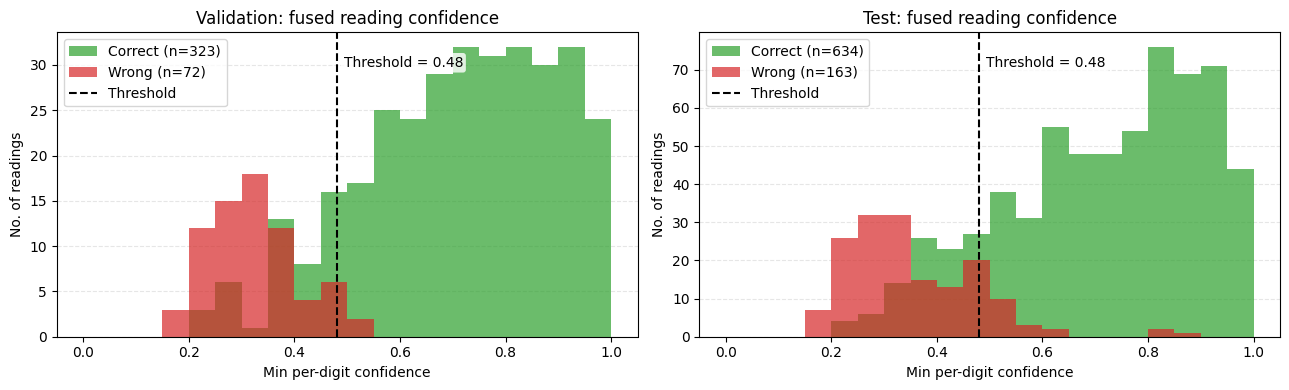

median confidence (end to end) - validation: correct 0.73, wrong 0.31; test: correct 0.75, wrong 0.33
not plotted (no detected counter, so no confidence; flagged automatically): validation 5, test 3


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
medians, misses = {}, {}
for ax, (split, key) in zip(axes, [("validation", "end_to_end_validation_predictions"), ("test", "end_to_end_predictions")]):
    p = pd.read_csv(resolve_path(CONFIG["paths"][key]))
    misses[split] = int((~p["detected"].astype(bool)).sum())
    p = p[p["detected"].astype(bool)]                                  # detector misses have no confidence to plot
    conf, ok = p["confidence"].to_numpy(), p["correct"].astype(bool).to_numpy()
    medians[split] = (np.median(conf[ok]), np.median(conf[~ok]))
    bins = np.linspace(0, 1, 21)
    ax.hist(conf[ok], bins=bins, alpha=0.7, color="#2ca02c", label=f"Correct (n={ok.sum()})")
    ax.hist(conf[~ok], bins=bins, alpha=0.7, color="#d62728", label=f"Wrong (n={(~ok).sum()})")
    ax.axvline(threshold, color="black", linestyle="--", linewidth=1.5, label="Threshold")
    # value label beside the dashed line
    ax.annotate(f"Threshold = {threshold:.2f}", xy=(threshold, 0.9), xycoords=("data", "axes fraction"),
                xytext=(5, 0), textcoords="offset points", fontsize=10, va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
    ax.set_axisbelow(True)                                             # keep the grid behind the bars
    ax.grid(axis="y", linestyle="--", color="#e6e6e6", linewidth=0.8)  # light horizontal dashed background lines
    ax.set_title(f"{split.capitalize()}: fused reading confidence"); ax.set_xlabel("Min per-digit confidence"); ax.set_ylabel("No. of readings")
    ax.legend()
fig.tight_layout()
plt.show()
print("median confidence (end to end) - " + "; ".join(f"{s}: correct {c:.2f}, wrong {w:.2f}" for s, (c, w) in medians.items()))
print(f"not plotted (no detected counter, so no confidence; flagged automatically): validation {misses['validation']}, test {misses['test']}")

**Observation:** These are end-to-end readings (raw photo → detector → recognisers → fusion), the same as in Section 3. Wrong readings (red) sit at low confidence and correct ones (green) at high confidence, with some overlap. Everything left of the dashed line (0.48) goes to a person. The threshold itself was chosen on validation ground-truth crops (Section 2); the end-to-end histograms show it carries over.

#### 2. How the threshold was chosen

Moving the dashed line right flags more readings: more wrong ones are caught, but more correct ones are flagged needlessly. For each threshold on validation:

- **errors caught** = share of wrong readings flagged
- **correct flagged** = share of correct readings flagged
- **Youden's J** = errors caught − correct flagged

The threshold with the highest Youden's J wins (ties go to the lower one). The test split is not used.

In [3]:
conf, ok = load_fused(CONFIG["paths"]["fusion_val_probs"])       # validation readings: confidence, and whether correct
n_wrong, n_correct = int((~ok).sum()), int(ok.sum())

rows = []
for t in sorted({round(x, 2) for x in np.arange(0.1, 0.95, 0.1)} | {threshold}):    # every 0.1, plus the chosen value
    caught = int((conf[~ok] < t).sum())                          # wrong readings below the threshold (flagged)
    flagged = int((conf[ok] < t).sum())                          # correct readings below the threshold (flagged)
    rows.append({"threshold": t,
                 "errors caught": f"{caught}/{n_wrong} = {caught / n_wrong:.1%}",
                 "correct flagged": f"{flagged}/{n_correct} = {flagged / n_correct:.1%}",
                 "Youden's J": caught / n_wrong - flagged / n_correct})
display(pd.DataFrame(rows).style.format({"threshold": "{:.2f}", "Youden's J": "{:.3f}"}).hide(axis="index")
        .apply(lambda r: ["background-color: #fffdcc" if r["threshold"] == threshold else "" for _ in r], axis=1))
print(f"validation: {n_wrong} wrong and {n_correct} correct readings; highlighted row = chosen threshold")

threshold,errors caught,correct flagged,Youden's J
0.10,0/66 = 0.0%,0/334 = 0.0%,0.000
0.20,3/66 = 4.5%,0/334 = 0.0%,0.045
0.30,31/66 = 47.0%,15/334 = 4.5%,0.425
0.40,50/66 = 75.8%,30/334 = 9.0%,0.668
0.48,61/66 = 92.4%,48/334 = 14.4%,0.781
0.50,62/66 = 93.9%,54/334 = 16.2%,0.778
0.60,66/66 = 100.0%,97/334 = 29.0%,0.710
0.70,66/66 = 100.0%,151/334 = 45.2%,0.548
0.80,66/66 = 100.0%,209/334 = 62.6%,0.374
0.90,66/66 = 100.0%,271/334 = 81.1%,0.189


validation: 66 wrong and 334 correct readings; highlighted row = chosen threshold


best Youden's J 0.781 at threshold 0.48 (errors caught 92.4% - correct flagged 14.4%); config: 0.48


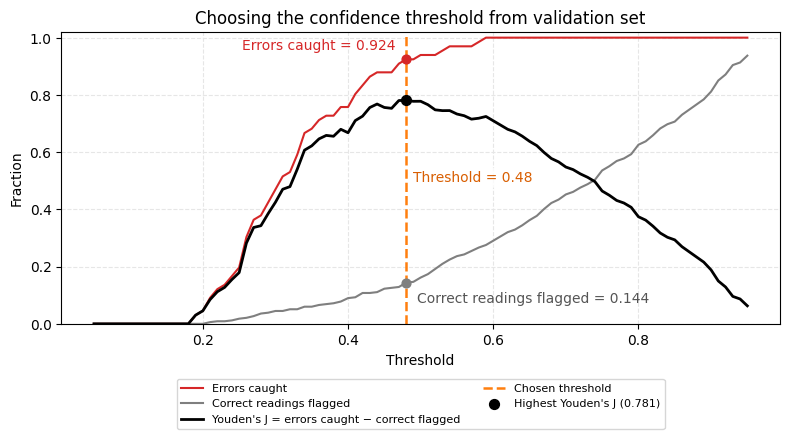

In [4]:
sw = pd.DataFrame(metrics["sweep"]["validation"])
sw["J"] = sw["errors_caught"] - sw["correct_flagged"]            # Youden's J: errors caught minus correct readings flagged
best = sw.loc[sw["J"].idxmax()]                                  # first maximum = lowest threshold, the same tie rule
print(f"best Youden's J {best['J']:.3f} at threshold {best['threshold']:.2f} "
      f"(errors caught {best['errors_caught']:.1%} - correct flagged {best['correct_flagged']:.1%}); config: {threshold:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(sw["threshold"], sw["errors_caught"], color="#d62728", label="Errors caught")
ax.plot(sw["threshold"], sw["correct_flagged"], color="#7f7f7f", label="Correct readings flagged")
ax.plot(sw["threshold"], sw["J"], color="black", linewidth=2, label="Youden's J = errors caught − correct flagged")
ax.axvline(threshold, color="#ff7f0e", linestyle="--", linewidth=1.8, label="Chosen threshold")
ax.scatter([best["threshold"]], [best["J"]], color="black", s=50, zorder=5, label=f"Highest Youden's J ({best['J']:.3f})")
# mark the values at the chosen threshold
ax.scatter([best["threshold"]], [best["errors_caught"]], color="#d62728", s=40, zorder=5)
ax.annotate(f"Errors caught = {best['errors_caught']:.3f}", xy=(best["threshold"], best["errors_caught"]), xytext=(-8, 7),
            textcoords="offset points", ha="right", color="#d62728", fontsize=10)
ax.scatter([best["threshold"]], [best["correct_flagged"]], color="#7f7f7f", s=40, zorder=5)
ax.annotate(f"Correct readings flagged = {best['correct_flagged']:.3f}", xy=(best["threshold"], best["correct_flagged"]),
            xytext=(8, -14), textcoords="offset points", ha="left", color="#555555", fontsize=10)
# value label beside the dashed line
ax.annotate(f"Threshold = {threshold:.2f}", xy=(threshold, 0.5), xycoords=("data", "axes fraction"),
            xytext=(5, 0), textcoords="offset points", color="#d95f02", fontsize=10, va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
ax.set_axisbelow(True)
ax.grid(True, linestyle="--", color="#e6e6e6", linewidth=0.8)    # light background grid
ax.set_xlabel("Threshold"); ax.set_ylabel("Fraction"); ax.set_ylim(0, 1.02)
ax.set_title("Choosing the confidence threshold from validation set")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
fig.tight_layout()
plt.show()

#### 3. Results at the chosen threshold (end to end)

Every reading comes from a raw photo through the full pipeline (`results/evaluation/end_to_end_*_predictions.csv`). Detector misses count as wrong, flagged readings. The last row uses ground-truth crops instead, for reference (recognisers and decision layer only).

In [5]:
rows = []
for split, key in (("validation", "end_to_end_validation_predictions"), ("testing", "end_to_end_predictions")):
    p = pd.read_csv(resolve_path(CONFIG["paths"][key]), dtype={"truth": str, "fused_reading": str})
    ok = p["correct"].astype(bool); app = p["decision"] == "APPROVED"
    r = json.load(open(resolve_path(CONFIG["paths"]["evaluation_summary"])))["end_to_end_validation" if split == "validation" else "end_to_end_test"]["decision"]
    assert int(app.sum()) == r["approved_count"] and int((app & ~ok).sum()) == r["errors_approved"]   # matches evaluate.py
    rows.append({"split": split, "readings": len(p), "correct readings": int(ok.sum()), "wrong readings": int((~ok).sum()),
                 "flagged readings": int((~app).sum()), "flag rate": float((~app).mean()),
                 "errors caught": float((~ok & ~app).sum() / (~ok).sum()),
                 "approved readings": int(app.sum()), "approved accuracy": float(ok[app].mean()),
                 "errors approved": int((app & ~ok).sum())})
gt = json.load(open(resolve_path(CONFIG["paths"]["evaluation_summary"])))["decision_ground_truth_crops"]["testing"]
table = [{"Setting": "End to end, validation", **{k: rows[0][k] for k in ("flag rate", "errors caught", "approved accuracy", "errors approved")}},
         {"Setting": "End to end, test (deployed)", **{k: rows[1][k] for k in ("flag rate", "errors caught", "approved accuracy", "errors approved")}},
         {"Setting": "GT crops, test (reference)", "flag rate": gt["flag_rate"], "errors caught": gt["errors_caught"],
          "approved accuracy": gt["approved_accuracy"], "errors approved": gt["errors_approved"]}]
table = pd.DataFrame(table).rename(columns=str.capitalize)
display(table.style.format({"Flag rate": "{:.1%}", "Errors caught": "{:.1%}", "Approved accuracy": "{:.1%}"}).hide(axis="index"))

Setting,Flag rate,Errors caught,Approved accuracy,Errors approved
"End to end, validation",28.7%,96.1%,98.9%,3
"End to end, test (deployed)",28.9%,84.3%,95.4%,26
"GT crops, test (reference)",26.1%,86.6%,96.6%,20


- **Flag rate** = flagged readings ÷ readings: the share sent to a person for review.
- **Errors caught** = wrong readings that were flagged ÷ all wrong readings.
- **Approved accuracy** = correct readings among the approved ÷ approved readings.
- **Errors approved** = wrong readings that were approved anyway (the misses).

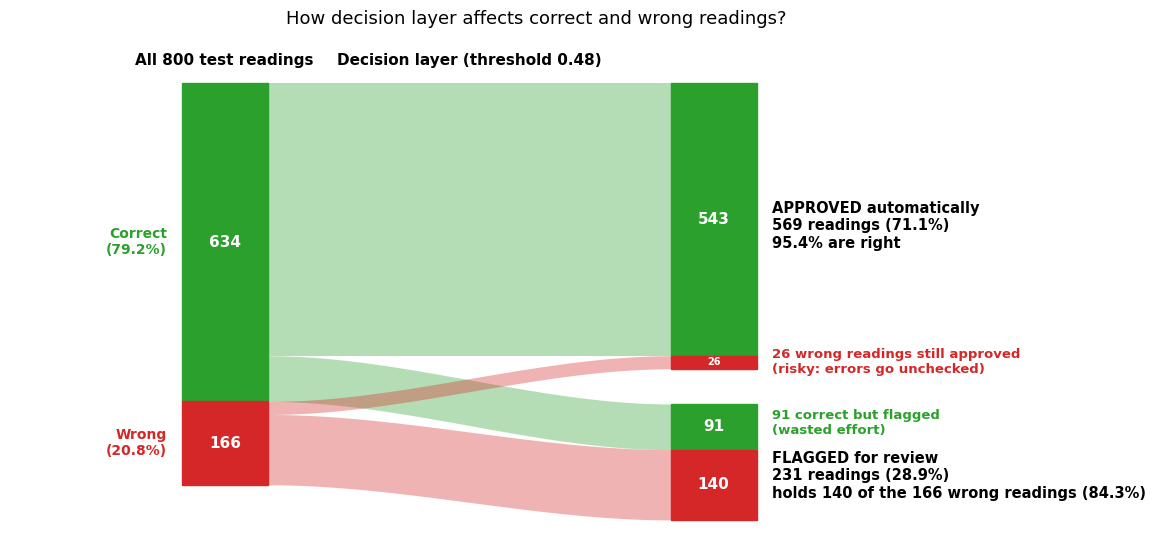

In [6]:
# plot_decision_flow() is defined in src/decision.py; evaluate.py saves the same figure to
# results/decision/decision_layer_effect.png (shown again in 09_evaluation.ipynb and the Inspector).
# split the test row above into correct/wrong x approved/flagged
t = rows[-1]
wrong_approved = t["errors approved"]                                  # wrong, but approved
wrong_flagged = t["wrong readings"] - wrong_approved                   # wrong, and flagged (caught)
correct_approved = t["approved readings"] - wrong_approved             # correct, and approved
correct_flagged = t["correct readings"] - correct_approved             # correct, but flagged
plot_decision_flow(correct_approved, correct_flagged, wrong_approved, wrong_flagged, threshold,
                   title="How decision layer affects correct and wrong readings?")
plt.show()

**Observation:** On the end-to-end test set, the diagram shows the same numbers as the table above. The left bar is all 800 test photos, split into correct (green, 634) and wrong (red, 166). The right bars show what happens to each group: 569 readings are approved (26 of them wrong, the "errors approved") and 231 are flagged for review. Most of the green is approved and most of the red is flagged.

- **Approved (71%):** 569 of the 800 readings are approved automatically, and 543 of them (95%) are correct.
- **Flagged (29%):** 231 readings go to review and hold 140 of the 166 wrong readings (84%).
- **Net effect:** a person reviews 231 readings instead of 800, and the readings that skip review are right 95% of the time, up from 79% (634 of 800) before the layer.
- **Wrong but approved:** 26 wrong readings (16% of the errors) go unchecked.
- **Correct but flagged:** 91 correct readings (14% of the correct ones) are reviewed unnecessarily.

On ground-truth crops (recognisers only, no detector) the same layer does a little better, approving 591 readings at 97% with 20 errors missed, because the detector adds errors that can still look confident.
